# Aperture toy ring

In the previous notebook we built the lattice of the toy ring. Here we build an aperture model for the same line.

The important modelling choice is that the aperture model is not forced to have one pipe per lattice element. Instead we use a small set of reusable pipe descriptions:

- curved elliptical pipes for the arc bends;
- octagonal straight pipes for the quadrupoles;
- circular straight pipes for ordinary drifts;
- one aggregate chicane chamber installed from `chicane.start` to `chicane.end`;
- short transition pipes, between neighbouring main pipes.

The construction below is deliberately split in two phases. First we build and place the main pipes. Then we inspect the gaps between those main pipes and place the required transition pipes. This keeps the aperture model tied to physical neighbours rather than to automatically generated drift names.

In [1]:
import warnings
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

# Ignore annoying matplotlib warnings
logging.getLogger("matplotlib").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=RuntimeWarning)

env = xt.load('toy_ring.json')
ring = env["ring"]
table = ring.get_table()
survey = ring.survey()

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Profiles and pipes belong to the environment, while their placements and the built aperture model belong to the line. We can define the geometry incrementally and build the model once all pipes are placed.

In [2]:
env.aperture  # collection of pipes and profiles shared in the Environment

<EnvAperture: 0 pipes, 0 profiles>

In [3]:
model = ring.aperture
model  # aperture model of `ring` comprised of the building blocks from `env.aperture`

<LineAperture: 0 pipe positions>

## Profiles

Profiles are transverse cross sections. Let's create the profiles used by the current model:

- `arc_ellipse` for the dipole chambers
- `quad_octagon` for quadrupoles
- `drift_circle` for ordinary drift space
- `ip_entry` and `ip_chamber` for the widened chicane insertion

In [4]:
arc_ellipse = env.aperture.new_profile(
    "arc_ellipse",
    "Ellipse",
    a=0.055,
    b=0.034,
)
quad_octagon = env.aperture.new_profile(
    "quad_octagon",
    "Octagon",
    max_x=0.048,
    max_y=0.048,
    max_diagonal=0.050,
)
drift_circle = env.aperture.new_profile(
    "drift_circle",
    "Circle",
    radius=0.040,
)
ip_entry = env.aperture.new_profile(
    "ip_entry",
    "RectEllipse",
    max_x=0.110,
    max_y=0.045,
    a=0.125,
    b=0.055,
)
ip_chamber = env.aperture.new_profile(
    "ip_chamber",
    "Racetrack",
    max_x=0.270,
    max_y=0.055,
    a=0.012,
    b=0.010,
)

The same profiles are accessible through `ring.aperture.profiles`. We can list their names,
inspect a shape's parameters, or obtain the polygon used to draw it:


In [5]:
print(ring.aperture.profiles.keys())
profile = ring.aperture.profiles["arc_ellipse"]
print(profile.shape)
profile_polygon = profile.build_polygon(len_points=128)
profile_polygon[:5]


['arc_ellipse', 'quad_octagon', 'drift_circle', 'ip_entry', 'ip_chamber']
Ellipse(a=0.055, b=0.034)


array([[0.055     , 0.        ],
       [0.05488177, 0.00222816],
       [0.05453078, 0.00443172],
       [0.05395756, 0.00658826],
       [0.05317786, 0.00867912]])

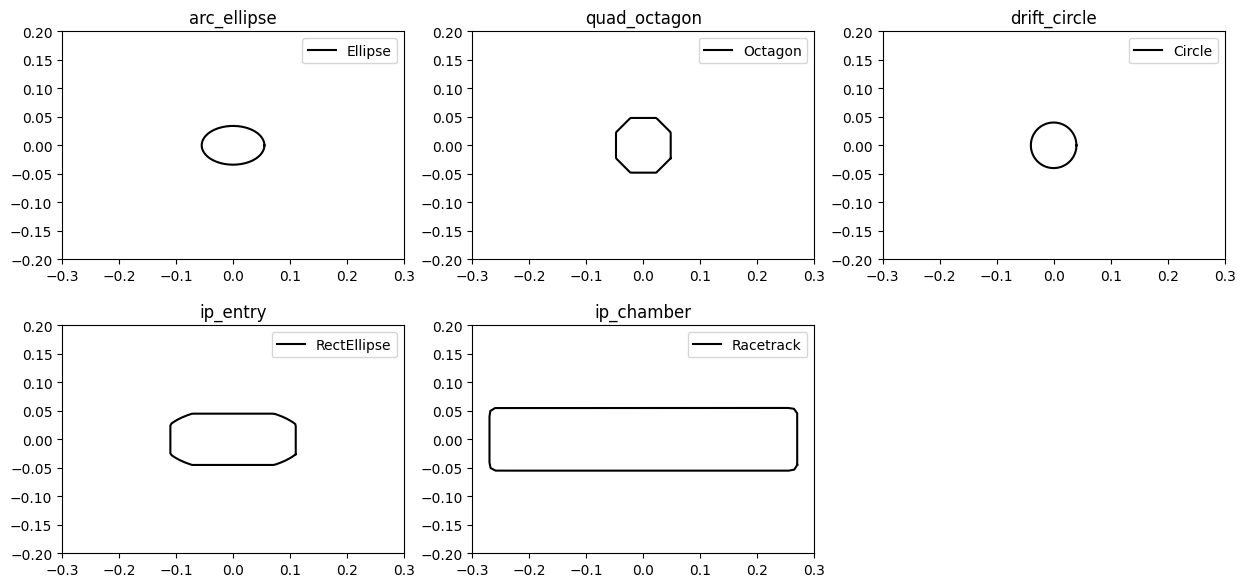

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
profile_names = ["arc_ellipse", "quad_octagon", "drift_circle", "ip_entry", "ip_chamber"]

for ax, profile_name in zip(axs.ravel(), profile_names):
    profile = env.aperture.profiles[profile_name]
    profile.plot(ax=ax)
    ax.set_title(profile_name)
    ax.legend()
    ax.set_xlim(-0.3, 0.3)
    ax.set_ylim(-0.2, 0.2)

for ax in axs.ravel()[len(profile_names):]:
    ax.axis("off")

## Main pipes

A pipe is a longitudinal sequence of installed profiles. The same pipe can later be installed many times at different survey references.

### Arc bend pipe

The bend pipe follows the bending radius of the `mb` element and uses the same elliptical profile at both ends.

In [7]:
l_mb = env["mb"].length
ang_mb = env["mb"].angle

arc_bend_pipe = env.aperture.new_pipe(
    "arc_bend_pipe",
    curvature=ang_mb / l_mb,
    positions=[
        arc_ellipse.place(shift_s=0.0),
        arc_ellipse.place(shift_s=l_mb),
    ],
)

To inspect the pipe behind these plots, use `ring.aperture.pipes`. A pipe can be iterated
or indexed to access its profile positions and their properties:


In [8]:
pipe = ring.aperture.pipes["arc_bend_pipe"]
print(f"Length: {pipe.length:.3f} m; curvature: {pipe.curvature:.3f} 1/m")
[(pos.profile.name, pos.shift_s) for pos in pipe]


Length: 1.203 m; curvature: 0.218 1/m


[('arc_ellipse', np.float64(0.0)),
 ('arc_ellipse', np.float64(1.203433809014149))]

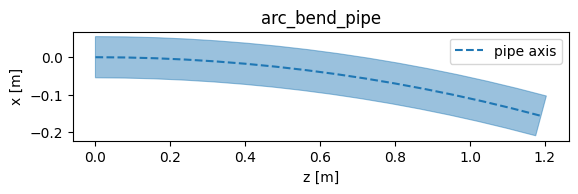

In [9]:
arc_bend_pipe.plot();

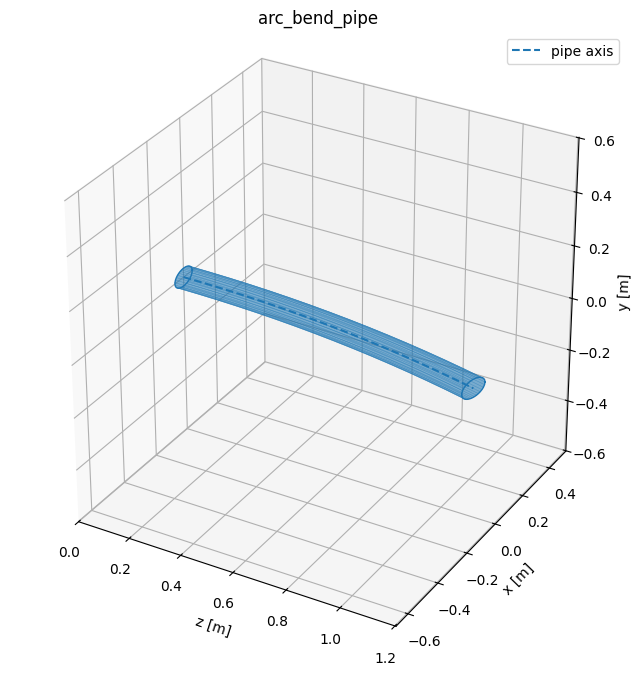

In [10]:
arc_bend_pipe.plot_3d(frame="curved");

### Quadrupole pipe

The quadrupole chamber is straight. We rotate the octagon slightly around the local pipe axis to make it visually distinct from an axis-aligned octagon.

In [11]:
l_mq = float(env["l_mq"])

quad_pipe = env.aperture.new_pipe(
    "quad_pipe",
    positions=[
        # we can specify transformations, e.g. rot_s_rad to rotate around local s
        quad_octagon.place(shift_s=0.0, rot_s_rad=np.deg2rad(22.5)),
        quad_octagon.place(shift_s=l_mq, rot_s_rad=np.deg2rad(22.5)),
    ],
)

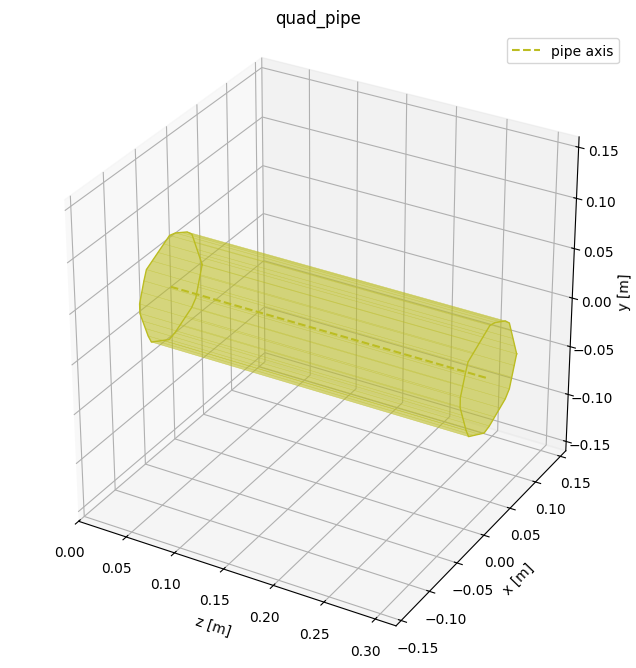

In [12]:
quad_pipe.plot_3d();

### Chicane pipe

The chicane is modelled as one aggregate chamber rather than four separate bend chambers. The lattice bends the reference trajectory outwards and back, meanwhile the aperture pipe is straight and installed from `chicane.start`.

In [13]:
chicane_z0 = float(survey.rows["chicane.start"].Z[0])
chicane_z1 = float(survey.rows["chicane.end"].Z[0])
ip_z = float(survey.rows["ip"].Z[0])

chicane_length = chicane_z1 - chicane_z0
ip_s = ip_z - chicane_z0
chamber_width = 5.0

chicane_pipe = env.aperture.new_pipe(
    "chicane_pipe",
    positions=[
        # Edge profiles are circles (smooth connection to neighbouring pipes)
        drift_circle.place(at=0.0),
        # Widen a bit 20 cm from the edges by installing `ip_entry`
        ip_entry.place(at=0.2),
        # Around the "IP" widen with `ip_chamber` and shift outwards
        ip_chamber.place(at=ip_s - chamber_width / 2, shift_x=0.15),
        ip_chamber.place(at=ip_s + chamber_width / 2, shift_x=0.15),
        ip_entry.place(at=chicane_length - 0.2),
        drift_circle.place(at=chicane_length),
    ],
)


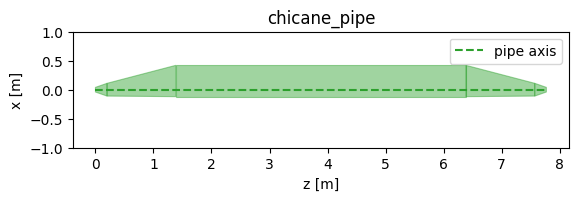

In [14]:
chicane_pipe.plot(plane="zx")
plt.ylim(-1, 1);

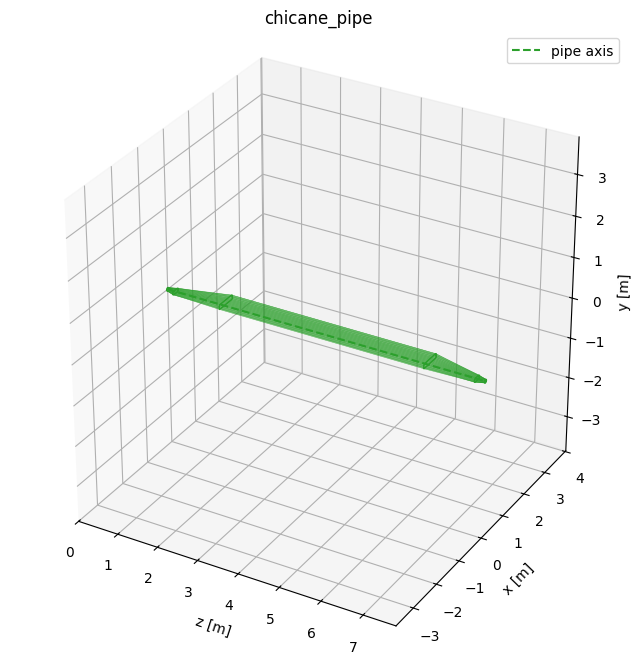

In [15]:
chicane_pipe.plot_3d();

### Straight-section drift pipe

The straight insertions between arcs use a circular drift pipe. We define the pipe around its centre (`shift_s=-s` and `shift_s=+s`) so that it can be installed directly at the midpoint markers `short.mid.*` and `utility.mid.*`.

In [16]:
sector_straight_length = chicane_length
straight_half_length = 0.5 * sector_straight_length - 1e-6

straight_pipe = env.aperture.new_pipe(
    "straight_pipe",
    positions=[
        drift_circle.place(at=-straight_half_length),
        drift_circle.place(at=straight_half_length),
    ],
)

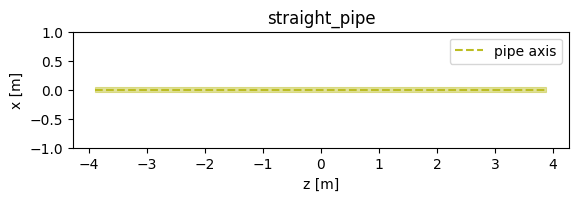

In [17]:
straight_pipe.plot()
plt.ylim(-1, 1);

## Install the main pipes

We now place all the main pipes.

At this step, there are some gaps in the model, which we will address afterwards by constructing another set of transition pipes.

In [18]:
mb_names = survey.rows[r'mb\..*'].name
quad_names = survey.rows[r'q[fd]\..*'].name
straight_names = survey.rows[r'(short.mid|utility.mid)\..*'].name

ring.aperture.place_pipe("chicane_pipe", chicane_pipe, at="chicane.start")

ring.aperture.place_pipe("arc_bend", arc_bend_pipe, at=mb_names)
ring.aperture.place_pipe("quad", quad_pipe, at=quad_names)
ring.aperture.place_pipe("straight", straight_pipe, at=straight_names)

ring.aperture

<LineAperture: 54 pipe positions>

## Transition pipes

**Currently, our model has gaps.** This is not, strictly speaking, a problem for us, as aperture computation routines will automatically interpolate the gaps. This happens along a straight line, and we do not have any gaps on arc sections. However, for completeness of the model, we will now construct transition pipes for our model.

### Identify the required transitions

After the main pipes are installed, the remaining aperture pieces are short transitions between neighbouring main pipes.

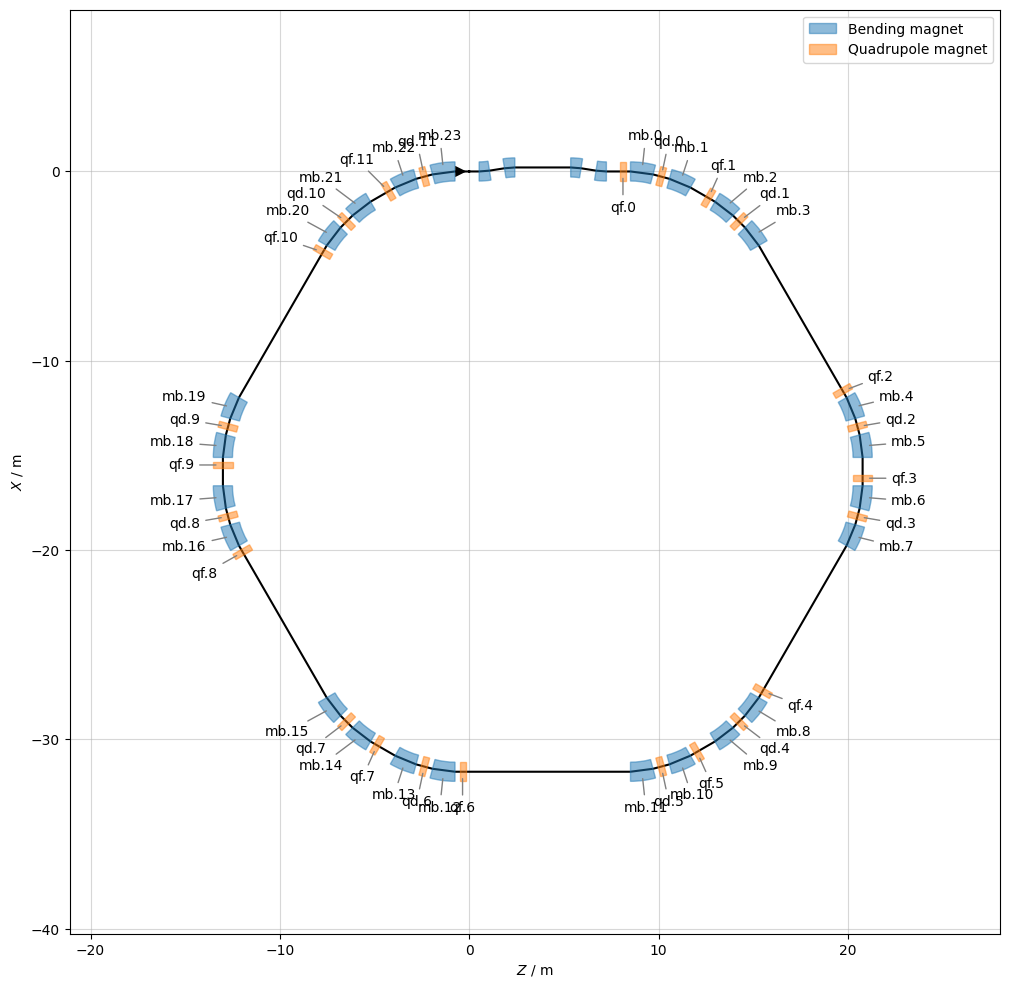

In [19]:
survey.plot(labels=[r'q[df]\..*', r'mb\..*'])
plt.gcf().set_figwidth(12)
plt.gcf().set_figheight(12)

Zooming into one cell of the arc, we can identify what transition pipes are needed:

Building cross-sections:   0%|          | 0/112 [00:00<?, ?it/s]

<EnvAperture: 4 pipes, 5 profiles>

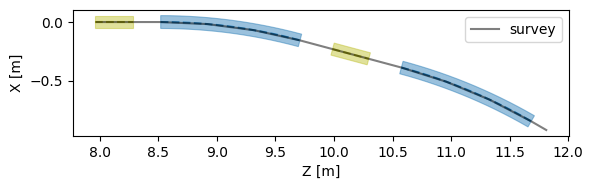

In [20]:
model.plot_floor_projection(s_range=(8, 12), aspect='equal')
env.aperture.discard_model()

In [21]:
cell_sv = env['arc_cell'].survey()
cell_sv.cols['name', 's', 'length']

SurveyTable: 10 rows, 3 cols
name                   s        length
||drift_1              0          0.19
qf                  0.19          0.32
||drift_2           0.51      0.238283
mb::0           0.748283       1.20343
||drift_3        1.95172      0.288283
qd                  2.24          0.32
||drift_4           2.56      0.288283
mb::1            2.84828       1.20343
||drift_5        4.05172      0.748283
_end_point           4.8             0

In the survey we can see that all the arcs, and all the straight sections (not counting the chicane) are the same.

Since we have placed pipes at all of the magnets, and at the chicane, the remaning parts of the aperture model that we still need to cover are the transitions between:
- chicane end/long straight section to `qf` of length 0.19 m
- `qf` and `mb` of length 0.238 m
- `mb` and `qd` of length 0.288 m (works in both directions)
- `mb` and the drift pipe

We will also need to construct a suitable pipe for the short straight section in the middle of the arc.

Let's collect some values:

In [22]:
edge_to_qf_len = cell_sv.rows[0].length[0]
qf_to_mb_len = cell_sv.rows['qf>>1'].length[0]
mb_to_qd_len = cell_sv.rows['mb::0>>1'].length[0]
qd_to_mb_len = cell_sv.rows['qd>>1'].length[0]
mb_to_edge_len = cell_sv.rows['mb::1>>1'].length[0]
mb_to_drift_len = edge_to_qf_len
edge_drift_len = mb_to_edge_len - mb_to_drift_len

# assert that we can reuse mb_to_qd pipe but "flipped"
assert np.isclose(mb_to_qd_len, qd_to_mb_len, rtol=0, atol=1e-6)
assert edge_drift_len > 0

print(f'- transition pipe from cell/straight edge to qf: {edge_to_qf_len} m')
print(f'- transition pipe from qf to mb: {qf_to_mb_len} m')
print(f'- transition pipe from mb to qd and qd to mb: {mb_to_qd_len} m')
print(f'- interface from mb to cell/straight edge: {mb_to_edge_len} m')
print(f'  - first {mb_to_drift_len} m transition from bend ellipse to drift circle')
print(f'  - remaining {edge_drift_len} m as circular drift pipe')

- transition pipe from cell/straight edge to qf: 0.18999999999999997 m
- transition pipe from qf to mb: 0.2382830954929256 m
- transition pipe from mb to qd and qd to mb: 0.2882830954929252 m
- interface from mb to cell/straight edge: 0.7482830954929254 m
  - first 0.18999999999999997 m transition from bend ellipse to drift circle
  - remaining 0.5582830954929254 m as circular drift pipe


### Construct the transition pipes

In [23]:
edge_qf_trans = env.aperture.new_pipe(
    'edge_qf_trans',
    positions=[
        drift_circle.place(at=0),
        quad_octagon.place(at=edge_to_qf_len),
    ],
)

In [24]:
qf_to_mb_trans = env.aperture.new_pipe(
    'qf_to_mb_trans',
    positions=[
        quad_octagon.place(at=0),
        arc_ellipse.place(at=qf_to_mb_len),
    ],
)

In [25]:
mb_to_qd_trans = env.aperture.new_pipe(
    'mb_to_qd_trans',
    positions=[
        arc_ellipse.place(at=0),
        quad_octagon.place(at=mb_to_qd_len, rot_s_rad=np.deg2rad(22.5)),
    ],
)

In [26]:
mb_to_edge_iface = env.aperture.new_pipe(
    'mb_to_edge_iface',
    positions=[
        arc_ellipse.place(at=0),
        drift_circle.place(at=0.19),
        drift_circle.place(at=mb_to_edge_len),
    ],
)

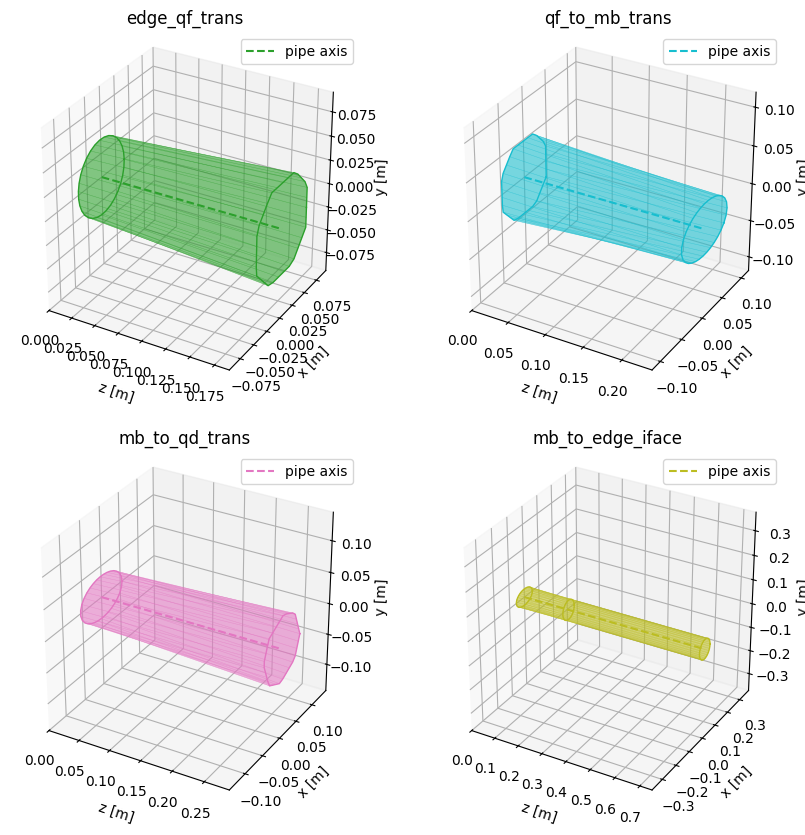

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10), subplot_kw={'projection': '3d'})
transition_names = ['edge_qf_trans', 'qf_to_mb_trans', 'mb_to_qd_trans', 'mb_to_edge_iface']

for ax, name in zip(axs.ravel(), transition_names):
    pipe = env.aperture.pipes[name]
    pipe.plot_3d(ax=ax)
    ax.set_title(name)
    ax.legend()

for ax in axs.ravel()[len(profile_names):]:
    ax.axis("off")

### Install the transition pipes

Now that the few transition pipes exist, installing them is mechanical. We use the physical neighbours as anchors.

In [28]:
qf_names = list(survey.rows[r'qf\..*'].name)
qd_names = list(survey.rows[r'qd\..*'].name)
mb_names = list(survey.rows[r'mb\..*'].name)

mb_to_qd_names = mb_names[0::2]
qd_to_mb_names = mb_names[1::2]

assert len(qf_names) == len(qd_names) == len(mb_to_qd_names) == len(qd_to_mb_names)

# `edge_qf_trans` ends at the start of each `qf`, so we place it at `qf@start`
ring.aperture.place_pipe(
    'edge_qf_trans', edge_qf_trans,
    at=[f'{name}@start' for name in qf_names],
    shift_z=-edge_to_qf_len,
)
# `qf_to_mb_trans` starts at the end of `qf`
ring.aperture.place_pipe(
    'qf_to_mb_trans', qf_to_mb_trans,
    at=[f'{name}@end' for name in qf_names],
)
# `mb_to_qd_trans` starts at the end of `mb`
ring.aperture.place_pipe(
    'mb_to_qd_trans', mb_to_qd_trans,
    at=[f'{name}@end' for name in mb_to_qd_names],
)
# `qd_to_mb_trans` reused backwards so we place it at `mb@start` and rotate by 180° around y
ring.aperture.place_pipe(
    'qd_to_mb_trans', mb_to_qd_trans,
    at=[f'{name}@start' for name in qd_to_mb_names],
    rot_y_rad=np.pi,
)
# `mb_to_edge_iface` starts at the end of the second bend in each cell
# and carries the pipe to the next cell edge/straight section/chicane
ring.aperture.place_pipe(
    'mb_to_edge_iface', mb_to_edge_iface,
    at=[f'{name}@end' for name in qd_to_mb_names],
)

[PipePosition(pipe_index=7, survey_reference_name='mb.1', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.3', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.5', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.7', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.9', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.11', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.13', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.15', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.17', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.19', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.21', survey_index=-1),
 PipePosition(pipe_index=7, survey_reference_name='mb.23', survey_index=-1)]

## Build and inspect the aperture model

All profiles and pipes are registered in the environment, and all placements belong to `ring.aperture`. Building freezes the placement survey and prepares derived geometry for computation.

In [29]:
print("num_profile_points =", model.num_profile_points)
print("s_tol =", model.s_tol)
model.build_model();

num_profile_points = 128
s_tol = 1e-06


Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

### The pipe table

The most basic way to inspect the model is to look at the pipe table, which lists all of the pipes and their locations:

In [30]:
pipe_table = model.get_pipe_table()
pipe_table

Table: 114 rows, 9 cols
name               pipe_name        survey_reference       s_start         s_end        length ...
chicane_pipe       chicane_pipe     chicane.start                0           7.8           7.8
edge_qf_trans.0    edge_qf_trans    qf.0                       7.8          7.99          0.19
quad.0             quad_pipe        qf.0                      7.99          8.31          0.32
qf_to_mb_trans.0   qf_to_mb_trans   qf.0                      8.31       8.54828      0.238283
arc_bend.0         arc_bend_pipe    mb.0                   8.54828       9.75172       1.20343
mb_to_qd_trans.0   mb_to_qd_trans   mb.0                   9.75172         10.04      0.288283
quad.1             quad_pipe        qd.0                     10.04         10.36          0.32
qd_to_mb_trans.0   mb_to_qd_trans   mb.1                     10.36       10.6483      0.288283
arc_bend.1         arc_bend_pipe    mb.1                   10.6483       11.8517       1.20343
mb_to_edge_iface.0 mb_

The columns of the pipe table are:

In [31]:
pipe_table.cols

ColView: name pipe_name survey_reference s_start s_end length s_span_start s_span_end span

In particular:
- `s_start` and `s_end` refer to the placement of the most extreme profiles of the pipe along the survey, where the profile's $s$-position is calculated as the intersection of the profile plane with the survey curve
- `s_span_start` and `s_span_end` refer, similarly, to the most extreme $s$-span positions of the pipe's profiles, where this is calculated by looking at all profile polygons placed in the survey frame, projecting their points onto the survey curve, and taking the most extreme values of $s$ obtained this way
- `length` refers simply to `s_end - s_start`, while `span` refers to `s_span_end - s_span_start`

If all the profiles are installed orthogonally to the survey, the `s_span_...` and `s_...` quantities are equal.

The pipe table is a **usual Xsuite table**, meaning all the same operations as on the twiss or survey table are supported.
E.g. to get the information about the pipe installed w.r.t. `mb.5`:

In [32]:
pt = ring.aperture.get_pipe_table()
pt.rows[pt.survey_reference == 'mb.5'].show()

name               pipe_name        survey_reference       s_start         s_end        length ...
qd_to_mb_trans.2   mb_to_qd_trans   mb.5                   27.7313       28.0196      0.288283
arc_bend.5         arc_bend_pipe    mb.5                   28.0196        29.223       1.20343
mb_to_edge_iface.2 mb_to_edge_iface mb.5                    29.223       29.9713      0.748283


### The aperture bounds table

We can investigate the positioning of all the profiles of all the pipes using the bounds table:

In [33]:
bounds_table = model.get_bounds_table()
bounds_table

Table: 244 rows, 8 cols
name               pipe_name     profile_name             s       s_start         s_end ...
chicane_pipe::0    chicane_pipe  drift_circle             0             0             0
chicane_pipe::1    chicane_pipe  ip_entry               0.2           0.2           0.2
chicane_pipe::2    chicane_pipe  ip_chamber         1.39179       1.35852         1.443
chicane_pipe::3    chicane_pipe  ip_chamber         6.40821         6.357       6.44148
chicane_pipe::4    chicane_pipe  ip_entry               7.6           7.6           7.6
chicane_pipe::5    chicane_pipe  drift_circle           7.8           7.8           7.8
edge_qf_trans.0::0 edge_qf_trans drift_circle           7.8           7.8           7.8
edge_qf_trans.0::1 edge_qf_trans quad_octagon          7.99          7.99          7.99
quad.0::0          quad_pipe     quad_octagon          7.99          7.99          7.99
quad.0::1          quad_pipe     quad_octagon          8.31          8.31          8.31
...


In [34]:
bounds_table.cols

ColView: name pipe_name profile_name s s_start s_end shape shape_param

Here it's the `s` values that determine the `s_start` and `s_end` of the pipe table, whereas `s_start` and `s_end` values determine the span.

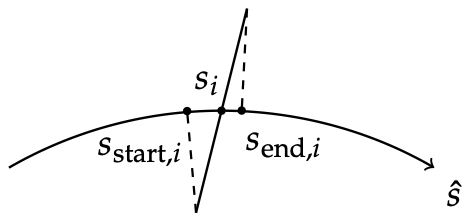

We can see that for the chicane pipe, the first two and the last two profiles have the same `s`, `s_start`, and `s_end`, and that this is true for most of the other profiles installed in the model.

However, the 3rd and 4rd profiles of the chicane pipe correspond at the location somewhere inside of the chicane bends, and so they are not installed orthogonally to the survey: this is reflected in the fact that `s`, `s_start`, and `s_end` values differ, and in particular.

### Floor plot

The most basic plot is the floor plot of the aperture model. Below we overlay the survey on top as well:

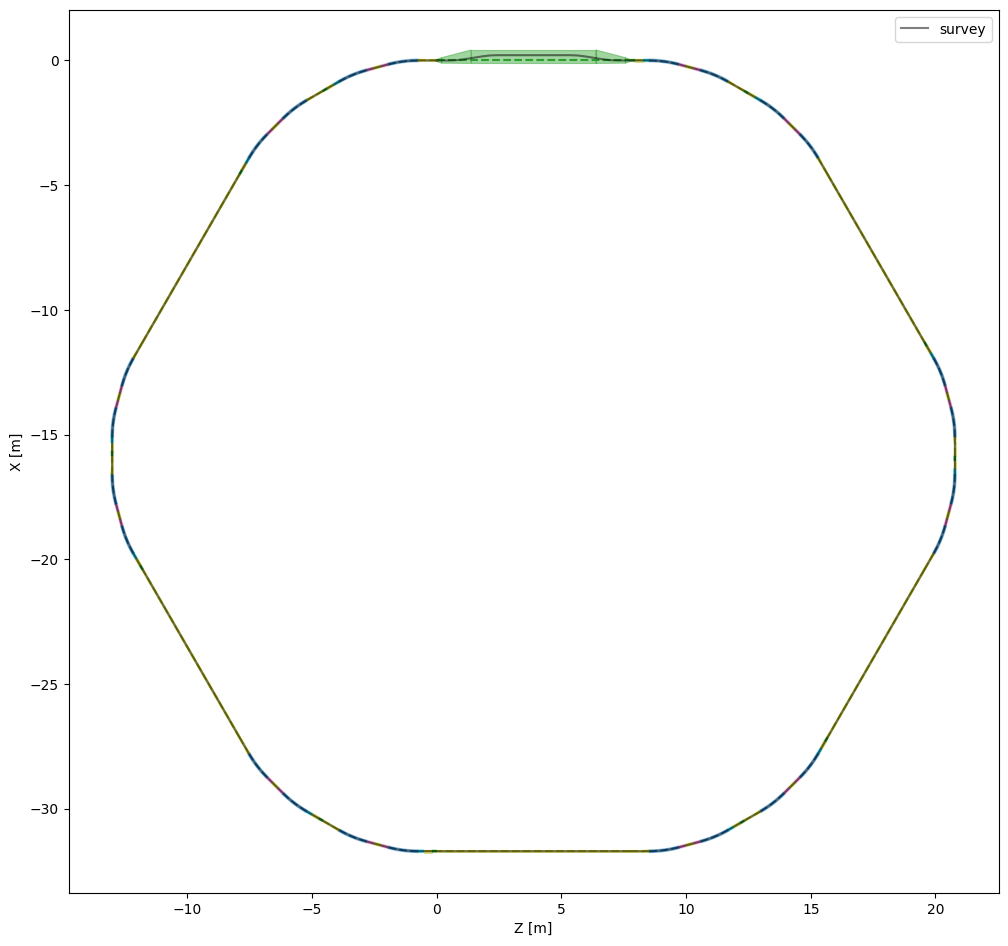

In [35]:
ax = model.plot_floor_projection(aspect='equal')
ax.figure.set_figwidth(12)
ax.figure.set_figheight(12)

We can also choose to only plot a smaller chunk of the model, specifying `origin` and `s_range`:

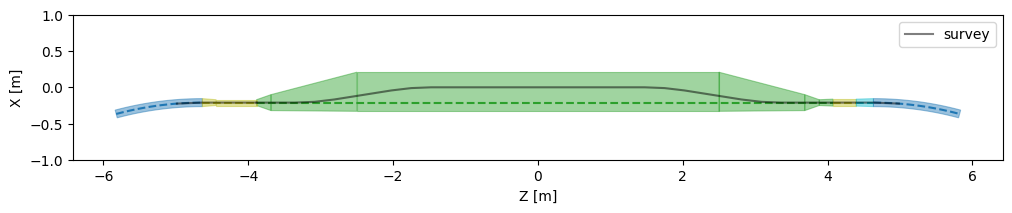

In [36]:
ax = model.plot_floor_projection(origin=3.9, s_range=(-5, 5))
# ax = model.plot_floor_projection(origin='edge_qf_trans.3', s_range=(-3, 3))
ax.set_aspect('equal')
ax.set_ylim(-1, 1)
plt.gcf().set_figwidth(12)

Each "box" in the floor plot corresponds to a placement in `ring.aperture.pipe_positions`.
These placements refer to reusable pipes in `ring.aperture.pipes`, which in turn contain
positions of profiles from `ring.aperture.profiles`. We can follow that chain directly:


In [37]:
# Chicane pipe
placement = ring.aperture.pipe_positions["chicane_pipe"]
placement

<PipePositionView 'chicane_pipe': 'chicane_pipe', survey_ref = 'chicane.start'>

In [38]:
# Iterate over individual profile positions
for pos in placement.pipe:
    profile = ring.aperture.profiles[pos.profile.name]
    print(pos)
    print("    => has shape ", pos.profile.shape)

<ProfilePositionView profile='drift_circle', shift_s=0.0>
    => has shape  Circle(radius=0.04)
<ProfilePositionView profile='ip_entry', shift_s=0.2>
    => has shape  RectEllipse(max_x=0.11, max_y=0.045, a=0.125, b=0.055)
<ProfilePositionView profile='ip_chamber', shift_s=1.3856349996184094>
    => has shape  Racetrack(max_x=0.27, max_y=0.055, a=0.012, b=0.01)
<ProfilePositionView profile='ip_chamber', shift_s=6.385634999618409>
    => has shape  Racetrack(max_x=0.27, max_y=0.055, a=0.012, b=0.01)
<ProfilePositionView profile='ip_entry', shift_s=7.571269999236819>
    => has shape  RectEllipse(max_x=0.11, max_y=0.045, a=0.125, b=0.055)
<ProfilePositionView profile='drift_circle', shift_s=7.771269999236819>
    => has shape  Circle(radius=0.04)


### Extents plot

The second useful type of plot is seeing the aperture limitation from the point of view of the beam.

For this we can use the `plot_extents` function, which requires a parameter `s_positions`: the $s$ positions at which we will sample the model to compute the cross section of the aperture model seen by the beam.

The convenience function `get_s_around_transitions` allows us to generate a list of $s$ positions with a given resolution, but also adding $s$ positions where the geometry of the model might change. This way, we can capture many of the points of interest of the model.

The extents plot shows the beam envelope at the maximum permissible size, but this can be tweaked using the `sigmas` parameter. The dashed line on the plot includes the aperture tolerances specified in the profile positions (and interpolated where necessary).

In [003_aperture_calculations.ipynb](003_aperture_calculations.ipynb), we will show how
to obtain these same aperture and beam-envelope data with equally simple calls, and
use them to make our own plots.


Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]

Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

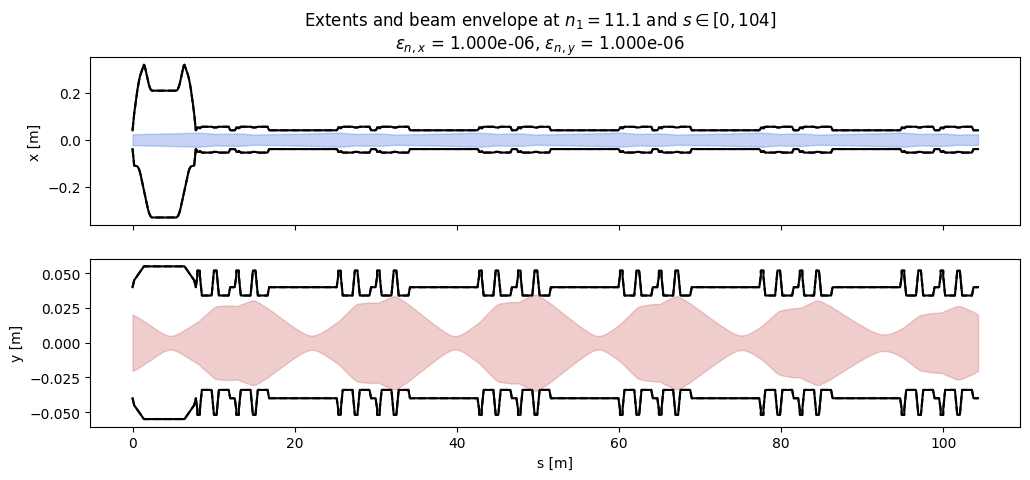

In [39]:
s_sample = model.get_s_around_transitions(resolution=0.1)
model.plot_extents(s_positions=s_sample)
plt.gcf().set_figwidth(12);

For example, we can see the beam at $1\sigma$ between $s = 20\,\text{m}$ and $s = 40\,\text{m}$ like so:

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Interpolating profiles: 100%

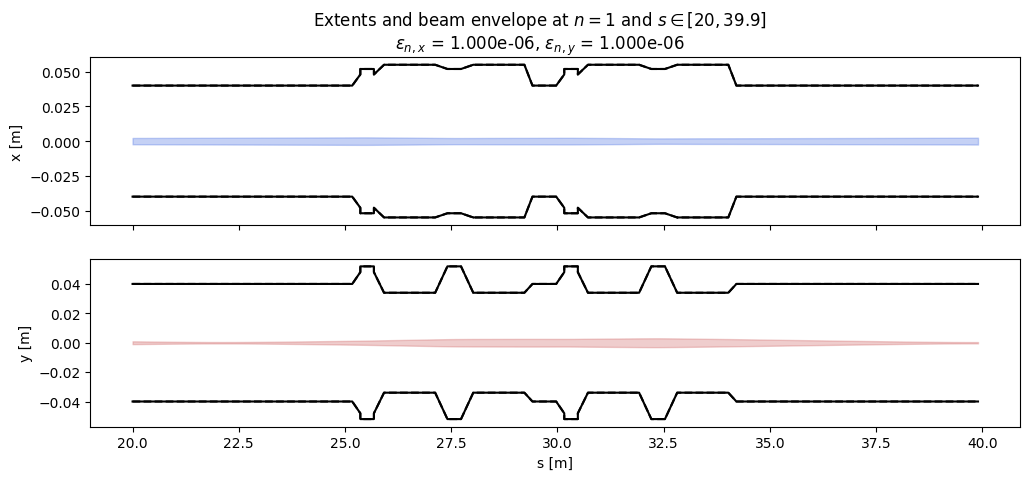

In [40]:
s_sample = model.get_s_around_transitions(resolution=0.1, s_range=(20, 40))
model.plot_extents(s_positions=s_sample, sigmas=1)
plt.gcf().set_figwidth(12);

### Save the aperture data to JSON

`env.aperture.to_json` saves the shared profiles and pipes, together with the placements
and settings of every named line in the environment (including `ring`). It saves the
aperture data separately from the lattice in `toy_ring.json`.

To restore it, first load the lattice, then call `env.aperture.from_json`.

Alternatively, `env.to_json("toy_ring_with_aperture.json", include_aperture=True)` saves the
lattice and aperture data together.

In [41]:
env.aperture.to_json('aperture_model.json')